# Lab 06 — Vision encoders: convolution, the Vision Transformer, DINOv2

**Book sections:** [3.1 Convolutional networks](../../book/docs/chapters/03-vision/cnn.md),
[3.2 The Vision Transformer](../../book/docs/chapters/03-vision/vit.md),
[3.3 Self-supervised encoders](../../book/docs/chapters/03-vision/self-supervised.md),
[3.4 Encoders for VLAs](../../book/docs/chapters/03-vision/encoders-for-vlas.md).

**Goal.** Build convolution and patch embedding by hand and check them against PyTorch; *measure*
translation equivariance and receptive fields instead of taking them on faith; train a small CNN and a
small ViT on depot scenes and watch inductive bias trade against data; then open a pretrained DINOv2 and
look at what its patch features know about the scene.

**Runtime:** ≈2 min with a GPU, ≈8 min on CPU. **Downloads:** ≈90 MB (DINOv2-small). **GPU:** optional
(< 1 GB). **Seed:** 0.

In [1]:
import os
import time
from pathlib import Path

os.environ.setdefault("HF_HOME", str(Path("../../data/hf").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from vlacourse.data import scenes
from vlacourse.seed import device, set_seed
from vlacourse.vision import PatchEmbed, ViT, resize_pos_embed, to_tensor

set_seed(0)
dev = device()
print("device:", dev)

device: cuda


## 1. Convolution by hand
A 2-D convolution layer with kernel $k$, $C_\text{in}$ input and $C_\text{out}$ output channels computes,
at every output location, a dot product between a $C_\text{in}\times k\times k$ window and each of
$C_\text{out}$ kernels. Written as matrices (book 3.1): unfold every window into a column (*im2col*),
then one matrix multiplication.

In [2]:
def conv2d_by_hand(x, weight, bias, stride=1, padding=0):
    """x: (B, C_in, H, W); weight: (C_out, C_in, k, k). Returns (B, C_out, H_out, W_out)."""
    B, C_in, H, W = x.shape
    C_out, _, k, _ = weight.shape
    H_out = (H + 2 * padding - k) // stride + 1
    W_out = (W + 2 * padding - k) // stride + 1
    cols = F.unfold(x, k, padding=padding, stride=stride)        # (B, C_in*k*k, H_out*W_out): one column per window
    out = weight.reshape(C_out, -1) @ cols + bias[:, None]        # (B, C_out, H_out*W_out)
    return out.reshape(B, C_out, H_out, W_out)


x = torch.randn(2, 3, 32, 32)
conv = nn.Conv2d(3, 16, kernel_size=5, stride=2, padding=2)
ours = conv2d_by_hand(x, conv.weight, conv.bias, stride=2, padding=2)
print("output shape", tuple(ours.shape), "  max |ours - torch| =", (ours - conv(x)).abs().max().item())
print("conv parameters:", sum(p.numel() for p in conv.parameters()),
      "  a dense layer with the same input/output sizes would need",
      f"{3 * 32 * 32 * 16 * 16 * 16:,}")

output shape (2, 16, 16, 16)   max |ours - torch| = 7.152557373046875e-07
conv parameters: 1216   a dense layer with the same input/output sizes would need 12,582,912


## 2. Translation equivariance, measured
Shift the image by $s$ pixels and compare the feature map of the shifted image with the shifted feature
map. For a stride-1 convolution with circular padding they are identical; for a ViT patch embedding
(stride $P$) they are identical only when $s$ is a multiple of $P$.

In [3]:
scene = scenes.random_scene(__import__("random").Random(4), n_objects=2)
img = to_tensor(scenes.render(scene, 64, texture=0)[None])            # (1, 3, 64, 64)
conv = nn.Conv2d(3, 8, 3, padding=1, padding_mode="circular", bias=False)
patch = PatchEmbed(8, 8)


def equivariance_error(f, s, stride=1):
    shifted_in = torch.roll(img, s, dims=3)
    fx, fsx = f(img), f(shifted_in)
    if fx.dim() == 3:                                                  # patch tokens (1, N, d) -> (1, d, g, g)
        g = int(fx.shape[1] ** 0.5)
        fx, fsx = (t.transpose(1, 2).reshape(1, -1, g, g) for t in (fx, fsx))
    if s % stride:
        return float("nan") if stride == 1 else (fsx - fx).norm().item() / fx.norm().item()
    return (fsx - torch.roll(fx, s // stride, dims=3)).norm().item() / fx.norm().item()


with torch.no_grad():
    for s in [1, 3, 8, 16]:
        print(f"shift {s:2d}px   conv 3x3 stride 1: rel. error {equivariance_error(conv, s):.1e}   "
              f"patch embed P=8: rel. error {equivariance_error(patch, s, stride=8):.2f}")

shift  1px   conv 3x3 stride 1: rel. error 0.0e+00   patch embed P=8: rel. error 0.17
shift  3px   conv 3x3 stride 1: rel. error 0.0e+00   patch embed P=8: rel. error 0.33


shift  8px   conv 3x3 stride 1: rel. error 0.0e+00   patch embed P=8: rel. error 0.00


shift 16px   conv 3x3 stride 1: rel. error 0.0e+00   patch embed P=8: rel. error 0.00


The convolution is exactly equivariant (error at floating-point precision). The patch embedding is
equivariant only for shifts that move whole patches; a 3-pixel shift changes every patch token by a
large relative amount. A ViT must *learn* robustness to small shifts from data and augmentation — one
concrete meaning of "weaker inductive bias" (book 3.2).

## 3. Receptive fields
The receptive field of an output unit is the set of input pixels that can affect it. Measure it with
autograd: back-propagate from one central output unit and see which input pixels get non-zero gradient.

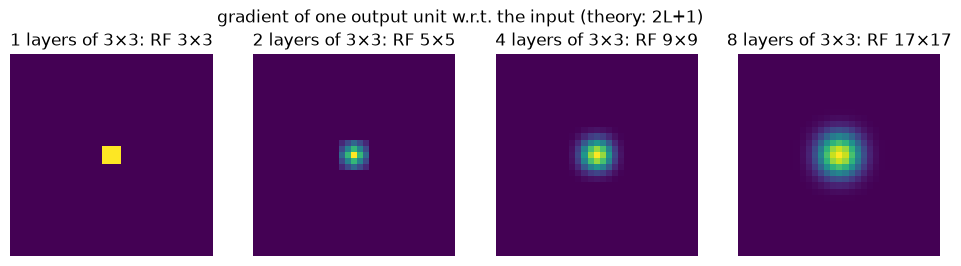

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for n_layers, ax in zip([1, 2, 4, 8], axs):
    net = nn.Sequential(*[nn.Sequential(nn.Conv2d(1, 1, 3, padding=1), nn.ReLU()) for _ in range(n_layers)])
    for m in net.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.constant_(m.weight, 1 / 9)
            nn.init.constant_(m.bias, 0.1)
    xin = torch.zeros(1, 1, 33, 33, requires_grad=True)
    net(xin)[0, 0, 16, 16].backward()
    g = xin.grad[0, 0]
    rf = int((g.abs().sum(0) > 0).sum())
    ax.imshow(g, cmap="viridis")
    ax.set_title(f"{n_layers} layers of 3×3: RF {rf}×{rf}")
    ax.axis("off")
plt.suptitle("gradient of one output unit w.r.t. the input (theory: 2L+1)")
plt.show()

The receptive field grows linearly, $2L+1$, and the gradient concentrates in the centre (it is a
repeated box filter, i.e. approximately Gaussian): the *effective* receptive field is smaller than the
theoretical one. A ViT has a global receptive field from its first layer.

## 4. Patch embedding is a strided convolution
Flatten each $P\times P\times 3$ patch and multiply by $W_E\in\mathbb{R}^{3P^2\times d}$ — or run a
convolution with kernel $=$ stride $=P$ whose kernel is $W_E$ reshaped. Same numbers.

In [5]:
pe = PatchEmbed(patch=8, d=32)
x = torch.randn(2, 3, 64, 64)
patches = F.unfold(x, kernel_size=8, stride=8).transpose(1, 2)        # (B, N_p, 3*8*8) raster order
W_E = pe.proj.weight.reshape(32, -1).T                                # (3P^2, d)
by_hand = patches @ W_E + pe.proj.bias                                # (B, N_p, d)
print("patches", tuple(patches.shape), "-> tokens", tuple(by_hand.shape),
      " max diff", (by_hand - pe(x)).abs().max().item())

patches (2, 64, 192) -> tokens (2, 64, 32)  max diff 8.344650268554688e-07


## 5. Inductive bias vs. data: a CNN and a ViT on depot scenes
Task: one object per image; predict its (kind, colour) — 16 classes. Two experiments, same training
budget for both architectures:

* **A — data size:** train on 100 or on 4000 random scenes, test on 2000 random scenes.
* **B — unseen positions:** train only on scenes whose object lies in the *left* half of the image,
  test on scenes whose object lies in the *right* half.

In [6]:
def make_split(n, seed, where=None):
    """n single-object scenes; where='left'/'right' keeps only objects in that half."""
    rng = __import__("random").Random(seed)
    sc = []
    while len(sc) < n:
        s = scenes.random_scene(rng, n_objects=1)
        if where is None or (s.objects[0].x < 0.5) == (where == "left"):
            sc.append(s)
    im = np.stack([scenes.render(s, 64, seed=seed * 100_003 + i) for i, s in enumerate(sc)])
    y = torch.tensor([scenes.KINDS.index(s.objects[0].kind) * 4 + list(scenes.COLORS).index(s.objects[0].color)
                      for s in sc])
    return to_tensor(im), y


class SmallCNN(nn.Module):
    def __init__(self, n_classes=16, w=32):
        super().__init__()
        def stage(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                                 nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(stage(3, w), stage(w, 2 * w), stage(2 * w, 4 * w))   # 64 -> 8
        self.head = nn.Linear(4 * w, n_classes)

    def forward(self, x):
        return self.head(self.features(x).mean((2, 3)))      # global average pooling


class ViTClassifier(nn.Module):
    def __init__(self, n_classes=16):
        super().__init__()
        self.vit = ViT(img_size=64, patch=8, d=128, n_layers=4, n_heads=4)
        self.head = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.head(self.vit.pooled(x))


def train_classifier(model, X, y, X_test, y_test, steps=400, bs=64, lr=1e-3):
    model = model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    for _ in range(steps):
        j = torch.randint(0, len(X), (bs,))
        loss = F.cross_entropy(model(X[j].to(dev)), y[j].to(dev))
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(X_test[k:k + 500].to(dev)).argmax(-1).cpu() for k in range(0, len(X_test), 500)])
    return (pred == y_test).float().mean().item()


X_all, y_all = make_split(4000, seed=1)
X_test, y_test = make_split(2000, seed=2)
X_left, y_left = make_split(4000, seed=3, where="left")
X_right, y_right = make_split(2000, seed=4, where="right")
experiments = [("A: 100 images", X_all[:100], y_all[:100], X_test, y_test),
               ("A: 4000 images", X_all, y_all, X_test, y_test),
               ("B: train left, test right", X_left, y_left, X_right, y_right)]
for exp, Xtr, ytr, Xte, yte in experiments:
    for name, ctor in [("CNN", SmallCNN), ("ViT", ViTClassifier)]:
        set_seed(0)
        t0 = time.time()
        acc = train_classifier(ctor(), Xtr, ytr, Xte, yte)
        print(f"{exp:28s} {name}: test accuracy {acc:.3f}  ({time.time() - t0:.0f} s)")
print("parameters: CNN", sum(p.numel() for p in SmallCNN().parameters()),
      " ViT", sum(p.numel() for p in ViTClassifier().parameters()))

A: 100 images                CNN: test accuracy 0.929  (12 s)


A: 100 images                ViT: test accuracy 0.636  (9 s)


A: 4000 images               CNN: test accuracy 1.000  (11 s)


A: 4000 images               ViT: test accuracy 0.988  (10 s)


B: train left, test right    CNN: test accuracy 1.000  (11 s)


B: train left, test right    ViT: test accuracy 0.972  (8 s)
parameters: CNN 289968  ViT 1084944


Read the table with book 3.1–3.2 in mind:

* **A, 100 images:** the CNN's built-in assumptions (locality, weight sharing) act as free knowledge and
  it generalises far better than the ViT. With 4000 images the gap almost closes: the ViT has learned
  those regularities from data.
* **B, unseen positions:** the CNN is perfect — convolution is translation-equivariant and global average
  pooling makes the class prediction translation-invariant *by construction*. The ViT also does well,
  because its patch embedding $W_E$ is shared by all patches (a weak form of weight sharing), but not
  perfectly: the learned position embeddings of the right half never saw an object during training.

This is the empirical story of Dosovitskiy et al. (2021) in miniature: ViTs overtake CNNs only after
pretraining on very large and varied datasets, which is why VLAs always use them *pretrained*.

## 6. A pretrained encoder: DINOv2-small
12 layers, width 384, 6 heads, patch 14, trained by self-distillation on 142 M curated images (book 3.3).
We feed it depot scenes at 224×224 → a 16×16 grid of patch tokens, plus a [CLS] token.
(`eager` attention so that the attention weights are returned; fused kernels never materialise them.)

In [7]:
from transformers import AutoModel

dino = AutoModel.from_pretrained("facebook/dinov2-small", attn_implementation="eager").to(dev).eval()
cfg = dino.config
print(f"d={cfg.hidden_size} L={cfg.num_hidden_layers} h={cfg.num_attention_heads} P={cfg.patch_size} "
      f"trained at {cfg.image_size}px; params {sum(p.numel() for p in dino.parameters()) / 1e6:.1f} M")
print("position-embedding table:", tuple(dino.embeddings.position_embeddings.shape),
      f"= 1 + {cfg.image_size // cfg.patch_size}^2")

rng = __import__("random").Random(11)
demo = [scenes.random_scene(rng, n_objects=3) for _ in range(3)]
imgs = np.stack([scenes.render(s, 224, size=0.2) for s in demo])
# DINOv2 expects ImageNet normalisation
x = torch.as_tensor(imgs).permute(0, 3, 1, 2).float().div(255)
x = ((x - torch.tensor([0.485, 0.456, 0.406])[:, None, None]) / torch.tensor([0.229, 0.224, 0.225])[:, None, None]).to(dev)
with torch.no_grad():
    out = dino(pixel_values=x, output_attentions=True)
tokens = out.last_hidden_state                                         # (B, 1 + 256, 384)
print("last_hidden_state", tuple(tokens.shape), "= [CLS] + 16x16 patches; (the table was interpolated 37x37 -> 16x16)")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

d=384 L=12 h=6 P=14 trained at 518px; params 22.1 M
position-embedding table: (1, 1370, 384) = 1 + 37^2
last_hidden_state (3, 257, 384) = [CLS] + 16x16 patches; (the table was interpolated 37x37 -> 16x16)


**PCA of patch features.** Project the 256 patch tokens of all three images onto their first three
principal components and display them as RGB. Nobody told DINOv2 what a toolbox is, yet its patch features
separate objects from floor and group patches of the same object.

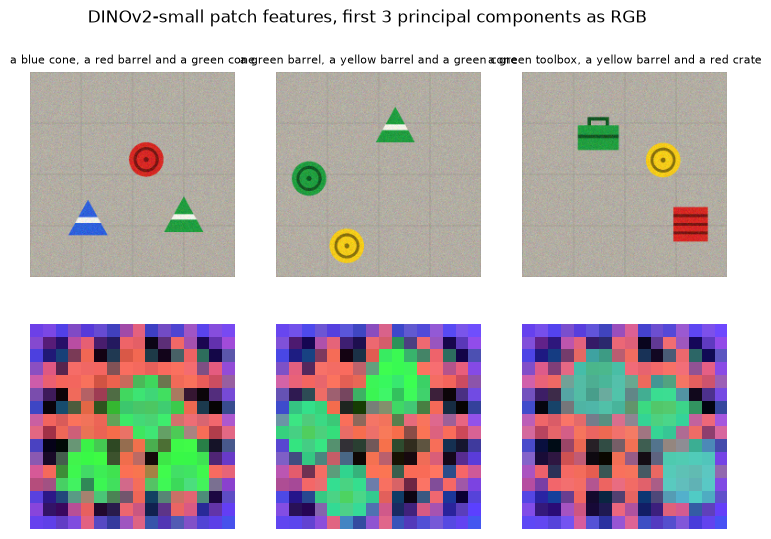

In [8]:
P = tokens[:, 1:].reshape(-1, cfg.hidden_size).float().cpu()
P = P - P.mean(0)
_, _, Vt = torch.linalg.svd(P, full_matrices=False)
proj = P @ Vt[:3].T
proj = (proj - proj.min(0).values) / (proj.max(0).values - proj.min(0).values)
fig, axs = plt.subplots(2, 3, figsize=(9, 6))
for i in range(3):
    axs[0, i].imshow(imgs[i])
    axs[0, i].set_title(scenes.caption(demo[i]), fontsize=8)
    axs[1, i].imshow(proj[i * 256:(i + 1) * 256].reshape(16, 16, 3))
for a in axs.flat:
    a.axis("off")
plt.suptitle("DINOv2-small patch features, first 3 principal components as RGB")
plt.show()

**[CLS] attention.** In the last layer, where does the [CLS] token read from? (Averaged over heads.)

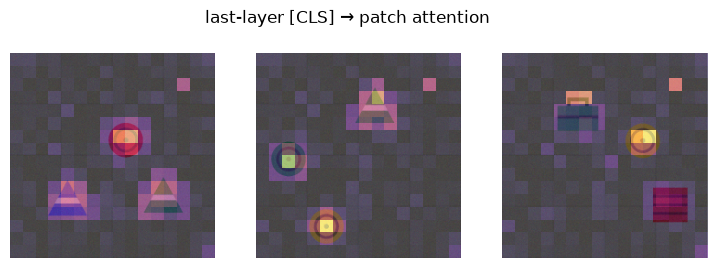

In [9]:
att = out.attentions[-1][:, :, 0, 1:].mean(1).reshape(-1, 16, 16).cpu()   # (B, 16, 16)
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for i, a in enumerate(axs):
    a.imshow(imgs[i])
    a.imshow(att[i], cmap="magma", alpha=0.6, extent=(0, 224, 224, 0))
    a.axis("off")
plt.suptitle("last-layer [CLS] → patch attention")
plt.show()

The [CLS] token reads mostly from the object patches. Notice also one isolated *background* patch that
receives strong attention in every image: large ViTs repurpose a few uninformative patches as global
scratch space, producing high-norm "artifact" tokens — the phenomenon that motivated adding extra
*register tokens* to ViTs (Darcet et al., 2024; book 3.2). Check it: print the norms of the patch tokens.

In [10]:
norms = tokens[:, 1:].norm(dim=-1).cpu()                                 # (B, 256)
print("patch-token norm: median", norms.median().item(), " max", norms.max().item(),
      " argmax per image", norms.argmax(-1).tolist(), "(raster index; 16 per row)")

patch-token norm: median 48.662967681884766  max 53.82892608642578  argmax per image [45, 45, 45] (raster index; 16 per row)


## 7. Resolution is a token budget
Tokens grow as $(H/P)^2$ and attention cost as its square. Time DINOv2-small at several resolutions
(each run interpolates the position table — book 3.2).

In [11]:
rows = []
for res in [224, 336, 448, 518]:
    xr = torch.randn(1, 3, res, res, device=dev)
    with torch.no_grad():
        dino(pixel_values=xr)                                              # warm-up
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(5):
            dino(pixel_values=xr)
        if dev.type == "cuda":
            torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / 5 * 1000
    n = (res // 14) ** 2
    rows.append((res, n, ms))
    print(f"{res}px -> {n:5d} patch tokens, {ms:6.1f} ms per image on {dev.type}")

# Our own interpolation helper does the same as the library's:
print("our resize of a 37x37 table to 16x16:", tuple(resize_pos_embed(dino.embeddings.position_embeddings, 16).shape))

224px ->   256 patch tokens,    7.7 ms per image on cuda
336px ->   576 patch tokens,   17.4 ms per image on cuda


448px ->  1024 patch tokens,   36.2 ms per image on cuda


518px ->  1369 patch tokens,   47.2 ms per image on cuda
our resize of a 37x37 table to 16x16: (1, 257, 384)


Doubling the resolution quadruples the tokens; for a VLA those tokens also go through the language
backbone, every control step (book 3.4). Small objects seen from a drone need resolution; latency
budgets forbid it. This tension recurs in Chapters 5, 11 and 13.

## Exercises
1. Add a stride-2 convolution to §2. For which shifts is it equivariant? What does max pooling do?
2. Train the ViT in §5 without the shift augmentation. How much does the 500-image accuracy drop? And the CNN's?
3. Replace the ViT's [CLS] pooling by mean pooling of patch tokens. Any difference here? Why might it matter
   for localisation?
4. Compute DINOv2-small's FLOPs per image at 224 and 518 px with the formulas of book 2.7 and 3.2, and
   compare the ratio with your measured time ratio.
5. Robotics: a drone at 30 m sees a 40 cm toolbox. With a 90° horizontal field of view and a 224-pixel
   image, how many pixels wide is the toolbox? How many patches of 14 px? What resolution makes it span one
   full patch?